In [9]:
import geopandas as gpd
import pandas as pd
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import matplotlib.pyplot as plt

In [10]:
gdf_DZ22_results = gpd.read_file("Prepared data for regression/Kintore-Tealing-DZ22-X_Y.geojson")
gdf_DZ22_results = gdf_DZ22_results.set_index("outputAreaCode")
gdf_DZ22_results.sample(10)

,pop_total,area_sqkm,density_pop/sqkm,distance_to_route,DZ22_Name,IZ22_Name,LA_Name,UR22_8FOLD_MIN,p_children,mean_adult_age,...,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,cumulativeActivity,modelled_per_100,empirical,empirical_per_100,geometry
outputAreaCode,,,,,,,,,,,,,,,,,,,,,
S01013944,702,0.208801,3362.058950,6445.186305,Westhill Central - 03,Westhill Central,Aberdeenshire,2,0.173484,53.452218,...,0.417219,0.459227,0.012876,0.849432,0.563218,0.290128,0.041329,0.0,0.00,"POLYGON ((382785 806575, 382741 806565, 382729..."
S01014248,448,40.167777,11.153219,0.000000,Friockheim - 03,Friockheim,Angus,6,0.168950,55.280220,...,0.341772,0.487751,0.006682,0.621076,0.574074,32.483267,7.250729,28.0,6.25,"POLYGON ((353795 757028, 353890 756803, 353994..."
S01013908,763,0.229749,3321.010381,6661.163783,Inverurie South - 05,Inverurie South,Aberdeenshire,2,0.192802,56.199045,...,0.228528,0.500657,0.032852,0.551451,0.501629,0.210068,0.027532,0.0,0.00,"POLYGON ((377240 821235, 377256 821202, 377260..."
S01015489,503,0.095664,5257.990746,3841.883964,Kirkton - 02,Kirkton,Dundee City,1,0.295316,43.901734,...,0.331551,0.361277,0.009980,0.807540,0.522059,1.314555,0.261343,0.0,0.00,"POLYGON ((340018.455 733762.904, 340000 733774..."
S01013899,637,0.147985,4304.477024,7812.381450,Inverurie North - 04,Inverurie North,Aberdeenshire,2,0.155592,54.669866,...,0.332714,0.426128,0.004666,0.859155,0.593060,0.135181,0.021221,0.0,0.00,"POLYGON ((376674.662 822330.032, 376690 822313..."
S01015404,988,0.088134,11210.228233,6639.564044,Stobswell - 03,Stobswell,Dundee City,1,0.202675,37.310968,...,0.182375,0.437186,0.175879,0.199195,0.270335,0.254177,0.025726,0.0,0.00,"POLYGON ((341063.585 731141.408, 341021 731133..."
S01014274,686,0.318588,2153.252674,3752.427940,Forfar East - 06,Forfar East,Angus,2,0.201439,54.347748,...,0.316413,0.494220,0.004335,0.826979,0.608833,1.698869,0.247649,0.0,0.00,"POLYGON ((346825.047 751110.837, 346855.521 75..."
S01015430,872,0.129055,6756.808833,7567.344937,Douglas East - 02,Douglas East,Dundee City,1,0.269231,49.822556,...,0.166667,0.369738,0.011377,0.454650,0.447674,0.202006,0.023166,0.0,0.00,"POLYGON ((344600.571 732121.867, 344605.77 732..."
S01013817,522,14.851905,35.147007,5284.392981,"Fetteresso, Netherley and Catter - 04","Fetteresso, Netherley and Catter",Aberdeenshire,6,0.224265,54.163507,...,0.460808,0.391969,0.015296,0.861004,0.501818,0.099960,0.019149,0.0,0.00,"POLYGON ((388031.473 791886.141, 388023.062 79..."


In [11]:
chosen_columns = ["density_pop/sqkm", "distance_to_route", "UR22_8FOLD_MIN", "p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned","p_car_drive_commute"]
df_normalised = pd.DataFrame()
for col in chosen_columns:
    df_normalised[col] = gdf_DZ22_results[col]/gdf_DZ22_results[col].mean()


In [12]:
Y = np.array(gdf_DZ22_results["empirical_per_100"].map(lambda x:np.sign(x)))
gdf_DZ22_results["Y"] = Y
df_normalised["Y"] = Y


In [35]:
df_training = df_normalised.sample(int(np.floor(df_normalised.shape[0]*3/4))).copy()
df_validation = df_normalised.loc[~df_normalised.index.isin(df_training.index)].copy()

X = np.array(df_normalised.loc[:,chosen_columns])

X_training = np.array(df_training.loc[:,chosen_columns])
X_validation = np.array(df_validation.loc[:,chosen_columns])

Y_training = np.array(df_training["Y"])
Y_validation = np.array(df_validation["Y"])

In [36]:
svc = make_pipeline(StandardScaler(),
                    LinearSVC(random_state=0, tol=1e-5))

In [37]:
svc.fit(X_training, Y_training)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearsvc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](2,)","[0.,1.]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [39]:
svc.score(X_validation,Y_validation), svc.score(X,Y)

(0.9245283018867925, 0.9054373522458629)

In [51]:
df_validation["predicted"] = svc.predict(X_validation)

AttributeError: This 'Pipeline' has no attribute 'predict_proba'

In [41]:
df_validation["decision_func"] = svc.decision_function(X_validation)

In [42]:
df_validation

,density_pop/sqkm,distance_to_route,UR22_8FOLD_MIN,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,Y,predicted,decision_func
outputAreaCode,,,,,,,,,,,,,,,,,
S01013490,0.011242,1.269335,0.397930,1.291440,1.089220,1.729451,0.000000,1.654339,0.925333,1.674860,1.068334,1.660594,1.353987,1.054570,0.0,0.0,-0.817316
S01013499,0.012746,1.491882,0.397930,1.183788,1.108626,1.961687,0.000000,1.467960,0.902854,1.798562,1.144059,1.613488,1.390739,0.994700,0.0,0.0,-0.945500
S01013745,0.001082,1.102584,0.397930,1.145652,0.945187,0.946855,0.295670,1.254072,0.962343,1.229114,0.798791,0.685438,1.109837,1.082230,0.0,0.0,-0.874740
S01013803,0.010730,1.608007,2.387582,1.156795,1.073467,0.704768,4.132241,0.984030,1.052227,0.835446,0.910368,0.164254,0.939738,1.128199,0.0,0.0,-1.071093
S01013804,0.022733,1.609512,2.387582,1.175404,1.027036,0.998352,5.870265,1.428744,1.048950,1.213996,0.942311,0.253945,1.397783,1.072524,1.0,0.0,-1.032612
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S01015545,0.052123,0.558915,0.397930,1.385380,0.907549,1.237304,0.000000,1.621563,1.051641,1.393513,1.032104,0.538599,1.367148,1.115382,0.0,0.0,-0.872737
S01015550,0.021272,1.244881,0.397930,0.564417,1.123760,1.139034,0.219300,1.160303,1.037638,1.267763,1.260598,1.233446,1.428043,1.032651,0.0,0.0,-1.306103
S01016874,160.259907,1.785421,1.193791,0.875281,1.098258,1.553971,0.363576,1.053036,1.008564,1.406426,0.906890,0.758507,1.137901,1.035811,0.0,0.0,-1.160105


In [43]:
df_validation["empirical"] = gdf_DZ22_results["empirical"]

In [44]:
# gdf_DZ22_results["predicted"] = df_normalised["predicted"]
# gdf_DZ22_results["predicted_proba"] = df_normalised["predict_proba"]

In [45]:
gdf_DZ22_results["dummy"] = 1.0
df_validation["dummy"] = 1.0
pd.pivot_table(df_validation, index = "Y", columns = "predicted", values = ["dummy"], aggfunc = "count")
# May want to weight the OAs with representations higher, to try and reduce the false negatives.


dummy     
predicted   0.0  1.0
Y                   
0.0        95.0  NaN
1.0         8.0  3.0

In [46]:
svc.score(X,Y)

0.9054373522458629

In [63]:
import json

In [67]:
fitted_params:LinearSVC = svc.get_params()["linearsvc"]
fitted_params.coef_

array([[-0.01723783, -0.3000328 ,  0.26120262, -0.05793394,  0.22899152,
         0.09761571, -0.1714564 ,  0.1799434 , -0.1138167 , -0.07268986,
        -0.22716764, -0.17426516,  0.00713846, -0.28905065]])

In [68]:
# dict(zip(chosen_columns, list(fitted_params.coef_[0])))
# Not sure whether these have an interpretation for SVM.

{'density_pop/sqkm': np.float64(-0.01723783360122257),
 'distance_to_route': np.float64(-0.3000328022915202),
 'UR22_8FOLD_MIN': np.float64(0.2612026160458982),
 'p_children': np.float64(-0.05793393542502445),
 'mean_adult_age': np.float64(0.22899151817241706),
 'p_level_4': np.float64(0.09761571410836098),
 'p_green_heating': np.float64(-0.17145639705223226),
 'p_married': np.float64(0.17994339521140984),
 'p_born_in_UK': np.float64(-0.11381670476029906),
 'p_L1_to_L6': np.float64(-0.07268986092684251),
 'p_religion': np.float64(-0.22716763690090966),
 'p_nonchristian_religion': np.float64(-0.1742651569291113),
 'p_owned': np.float64(0.007138460919399071),
 'p_car_drive_commute': np.float64(-0.28905064500589295)}

Text(0, 0.5, 'empirical observations')

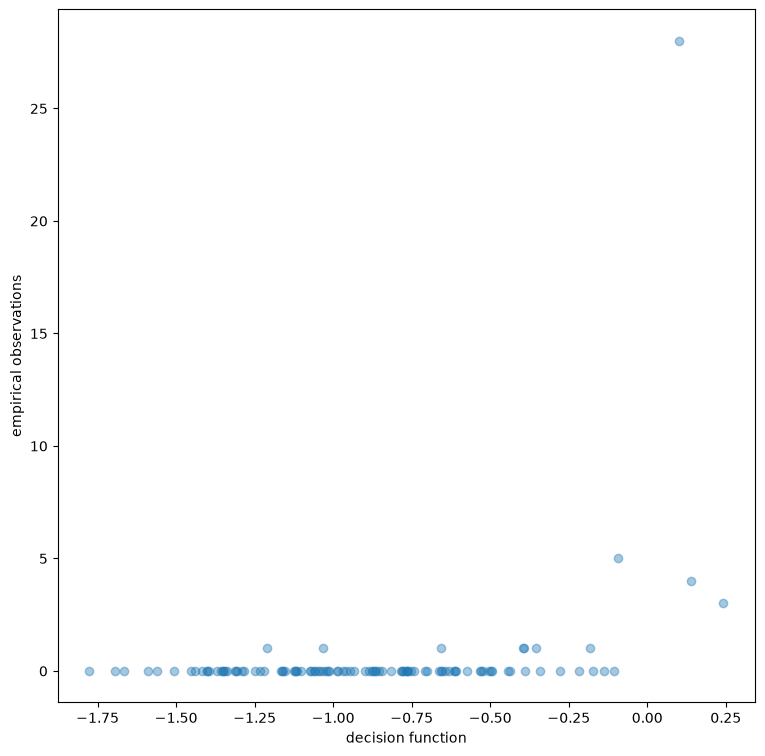

In [47]:
# I wonder if it would be better to separate distance in the statistic model.
fig, ax = plt.subplots(figsize = (9,9))
plt.scatter(df_validation["decision_func"], df_validation["empirical"], alpha = 0.4)
ax.set_xlabel("decision function")
ax.set_ylabel("empirical observations")